# Phase 14 — Leakage-Aware Model Re-training & Evaluation

**Project:** Australian Stock Market Analytics & Return Modeling

## Goal
Train a small set of regression models on the Phase 13 corrected target table using only the five candidate predictors discovered in the audit. Use explicit target endpoint dates to purge overlapping labels at chronological boundaries, fit preprocessing on training data only, and compare models against a training-mean baseline.

**Important:** This notebook is conditional on Phase 13 outputs. It includes diagnostic checks and refuses to proceed if the key files or required columns are missing. It does not assume that target reconstruction has been proven equivalent to Phase 9.

## 1. Setup and load Phase 13 artifacts

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
RANDOM_STATE = 42

FEATURE_REL = Path("data/processed/model_features/asx_3m_corrected_model_table.csv")
TRAIN_REL = Path("data/processed/model_features/asx_3m_strict_split_train.csv")
VALID_REL = Path("data/processed/model_features/asx_3m_strict_split_validation.csv")
TEST_REL = Path("data/processed/model_features/asx_3m_strict_split_test.csv")
AUDIT_REL = Path("reports/target_alignment_audit/phase13_target_alignment_summary.json")

def locate_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / FEATURE_REL).exists():
            return p
    for p in start.iterdir() if start.exists() else []:
        if p.is_dir() and (p / FEATURE_REL).exists():
            return p
    return None

PROJECT_ROOT = locate_root()
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find Phase 13 corrected model table. Run Phase 13 first.")
FEATURE_PATH = PROJECT_ROOT / FEATURE_REL
TRAIN_PATH = PROJECT_ROOT / TRAIN_REL
VALID_PATH = PROJECT_ROOT / VALID_REL
TEST_PATH = PROJECT_ROOT / TEST_REL
AUDIT_PATH = PROJECT_ROOT / AUDIT_REL

OUT = PROJECT_ROOT / "reports" / "corrected_model_training"
PRED_OUT = PROJECT_ROOT / "data" / "processed" / "corrected_model_predictions"
OUT.mkdir(parents=True, exist_ok=True)
PRED_OUT.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
for p in [FEATURE_PATH, TRAIN_PATH, VALID_PATH, TEST_PATH, AUDIT_PATH]:
    print(p.name, "exists:", p.exists())

Project root: e:\Projects\Australian Stock Market Data Science Project
asx_3m_corrected_model_table.csv exists: True
asx_3m_strict_split_train.csv exists: True
asx_3m_strict_split_validation.csv exists: True
asx_3m_strict_split_test.csv exists: True
phase13_target_alignment_summary.json exists: True


## 2. Load data and verify split boundaries

We use the split files generated in Phase 13, but independently check that each training/validation target endpoint falls before the next split starts. If the checks fail, stop rather than silently training on a potentially leaking split.

In [2]:
def load_split(path):
    part = pd.read_csv(path, low_memory=False)
    part.columns = [str(c).strip().lower() for c in part.columns]
    for col in ["date", "target_endpoint_date_3m"]:
        if col in part.columns:
            part[col] = pd.to_datetime(part[col], errors="coerce")
    if "ticker" in part.columns:
        part["ticker"] = part["ticker"].astype(str).str.strip().str.upper()
    if "forward_return_3m" in part.columns:
        part["forward_return_3m"] = pd.to_numeric(part["forward_return_3m"], errors="coerce")
    return part

if not all(p.exists() for p in [TRAIN_PATH, VALID_PATH, TEST_PATH]):
    raise FileNotFoundError("One or more Phase 13 strict split files are missing.")

train = load_split(TRAIN_PATH)
valid = load_split(VALID_PATH)
test = load_split(TEST_PATH)

required_cols = {"ticker", "date", "target_endpoint_date_3m", "forward_return_3m"}
for label, part in [("train", train), ("validation", valid), ("test", test)]:
    missing = required_cols - set(part.columns)
    if missing:
        raise ValueError(f"{label} split missing required columns: {sorted(missing)}")
    if part[["date", "target_endpoint_date_3m", "forward_return_3m"]].isna().any().any():
        raise ValueError(f"{label} split contains missing dates, endpoints, or targets.")

if len(train) == 0 or len(valid) == 0 or len(test) == 0:
    raise ValueError("One or more splits are empty.")

valid_start = valid["date"].min()
test_start = test["date"].min()
train_endpoint_max = train["target_endpoint_date_3m"].max()
valid_endpoint_max = valid["target_endpoint_date_3m"].max()

checks = {
    "train_endpoints_before_validation_start": bool(train_endpoint_max < valid_start),
    "validation_endpoints_before_test_start": bool(valid_endpoint_max < test_start),
    "train_max_endpoint": str(train_endpoint_max),
    "validation_start": str(valid_start),
    "validation_max_endpoint": str(valid_endpoint_max),
    "test_start": str(test_start),
    "train_rows": int(len(train)),
    "validation_rows": int(len(valid)),
    "test_rows": int(len(test))
}
print(json.dumps(checks, indent=2))
if not checks["train_endpoints_before_validation_start"] or not checks["validation_endpoints_before_test_start"]:
    raise ValueError("Endpoint leakage check failed. Rebuild Phase 13 split files before modeling.")

{
  "train_endpoints_before_validation_start": true,
  "validation_endpoints_before_test_start": true,
  "train_max_endpoint": "2025-02-17 00:00:00",
  "validation_start": "2025-02-18 00:00:00",
  "validation_max_endpoint": "2025-10-31 00:00:00",
  "test_start": "2025-11-03 00:00:00",
  "train_rows": 40447,
  "validation_rows": 6084,
  "test_rows": 9412
}


## 3. Select the five candidate predictors

Only the five candidate predictors from the Phase 13 allowlist are considered. Each feature must exist in the corrected table and should represent information available on or before the prediction date. This notebook checks names and values but cannot automatically prove feature timing.

In [3]:
candidate_features = [
    "momentum_21d",
    "momentum_63d",
    "benchmark_return_1d",
    "benchmark_volatility_21d",
    "benchmark_volatility_63d"
]
feature_cols = [c for c in candidate_features if c in train.columns]
missing_features = sorted(set(candidate_features) - set(feature_cols))
print("Predictors used:", feature_cols)
print("Allowlisted predictors missing:", missing_features)
if len(feature_cols) < 1:
    raise ValueError("No allowlisted predictor columns found in Phase 13 split files.")

# Explicitly prohibit identifiers, targets, endpoint metadata, and all non-allowlisted columns.
forbidden = {"ticker", "date", "target_endpoint_date_3m", "target_endpoint_price_3m",
             "forward_return_3m", "close_for_target", "target_horizon_observations"}
assert not (set(feature_cols) & forbidden)

for label, part in [("train", train), ("validation", valid), ("test", test)]:
    for col in feature_cols:
        part[col] = pd.to_numeric(part[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
    print(label, "shape:", part[feature_cols].shape,
          "| rows with at least one feature:", int(part[feature_cols].notna().any(axis=1).sum()))

Predictors used: ['momentum_21d', 'momentum_63d', 'benchmark_return_1d', 'benchmark_volatility_21d', 'benchmark_volatility_63d']
Allowlisted predictors missing: []
train shape: (40447, 5) | rows with at least one feature: 40396
validation shape: (6084, 5) | rows with at least one feature: 6084
test shape: (9412, 5) | rows with at least one feature: 9412


## 4. Prepare train, validation, and test matrices

Imputation and scaling are placed inside each pipeline. Their parameters are learned from the training set only. We do not use test data for feature selection or model selection.

In [4]:
X_train = train[feature_cols].copy()
y_train = train["forward_return_3m"].astype(float)
X_valid = valid[feature_cols].copy()
y_valid = valid["forward_return_3m"].astype(float)
X_test = test[feature_cols].copy()
y_test = test["forward_return_3m"].astype(float)

print("Target mean (train):", y_train.mean())
print("Target mean (validation):", y_valid.mean())
print("Target mean (test):", y_test.mean())
print("Train/validation/test:", len(train), len(valid), len(test))

Target mean (train): 0.021461323363067598
Target mean (validation): 0.07509823854607746
Target mean (test): -0.009887806217044012
Train/validation/test: 40447 6084 9412


## 5. Define compact candidate models

We use simple and tabular-data models. Results should be compared with the baseline and interpreted as a research experiment, not as trading advice.

In [5]:
models = {
    "Training mean baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyRegressor(strategy="mean"))
    ]),
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=10.0))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=300, min_samples_leaf=20, max_features=0.8,
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "HistGradientBoosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingRegressor(
            max_iter=150, learning_rate=0.05, max_leaf_nodes=15,
            l2_regularization=1.0, random_state=RANDOM_STATE
        ))
    ])
}

## 6. Train on training data and select by validation MAE

In [6]:
def metrics(y_true, y_pred):
    return {
        "n": int(len(y_true)),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)) if len(y_true) > 1 else np.nan,
        "actual_mean": float(np.mean(y_true)),
        "predicted_mean": float(np.mean(y_pred)),
        "mean_prediction_bias": float(np.mean(y_pred) - np.mean(y_true))
    }

val_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    val_pred = model.predict(X_valid)
    val_rows.append({"model": name, **metrics(y_valid, val_pred)})

validation_results = pd.DataFrame(val_rows).sort_values("MAE").reset_index(drop=True)
display(validation_results)
validation_results.to_csv(OUT / "corrected_validation_comparison.csv", index=False)

# Baseline is included in candidate comparison; avoid accidentally selecting it if another model has similar performance?
best_model_name = str(validation_results.iloc[0]["model"])
print("Selected by lowest validation MAE:", best_model_name)

,model,n,MAE,RMSE,R2,actual_mean,predicted_mean,mean_prediction_bias
0,Training mean baseline,6084,0.141984,0.195113,-0.081749,0.075098,0.021461,-0.053637
1,HistGradientBoosting,6084,0.142511,0.198628,-0.121080,0.075098,0.027535,-0.047563
2,Random Forest,6084,0.146571,0.204790,-0.191712,0.075098,0.030853,-0.044245
3,Ridge Regression,6084,0.147386,0.202863,-0.169392,0.075098,0.011043,-0.064055
4,Linear Regression,6084,0.147392,0.202870,-0.169472,0.075098,0.011037,-0.064061


Selected by lowest validation MAE: Training mean baseline


## 7. Refit selected model on train + validation, then evaluate once on test

The held-out test set is used only after model selection. The endpoint-based purge ensures train and validation labels end before the next period begins, according to the Phase 13 split files.

In [7]:
train_valid = pd.concat([train, valid], ignore_index=True).sort_values(["date", "ticker"])
X_train_valid = train_valid[feature_cols].copy()
y_train_valid = train_valid["forward_return_3m"].astype(float)

selected_model = clone(models[best_model_name])
selected_model.fit(X_train_valid, y_train_valid)
test_pred = selected_model.predict(X_test)

test_results = pd.DataFrame([{"model": best_model_name, **metrics(y_test, test_pred)}])
display(test_results)
test_results.to_csv(OUT / "corrected_heldout_test_metrics.csv", index=False)

baseline_value = float(y_train_valid.mean())
baseline_pred = np.full(len(y_test), baseline_value)
baseline_comparison = pd.DataFrame([
    {"model": "Train+validation mean baseline", **metrics(y_test, baseline_pred)},
    {"model": best_model_name, **metrics(y_test, test_pred)}
])
display(baseline_comparison)
baseline_comparison.to_csv(OUT / "corrected_test_baseline_comparison.csv", index=False)

test_predictions = test[["ticker", "date", "target_endpoint_date_3m", "forward_return_3m"]].copy()
test_predictions["predicted_forward_return_3m"] = test_pred
test_predictions["prediction_error"] = test_predictions["forward_return_3m"] - test_predictions["predicted_forward_return_3m"]
test_predictions.to_csv(PRED_OUT / "asx_3m_corrected_test_predictions.csv", index=False)

,model,n,MAE,RMSE,R2,actual_mean,predicted_mean,mean_prediction_bias
0,Training mean baseline,9412,0.143784,0.184964,-0.04495,-0.009888,0.028474,0.038362


,model,n,MAE,RMSE,R2,actual_mean,predicted_mean,mean_prediction_bias
0,Train+validation mean baseline,9412,0.143784,0.184964,-0.04495,-0.009888,0.028474,0.038362
1,Training mean baseline,9412,0.143784,0.184964,-0.04495,-0.009888,0.028474,0.038362


## 8. Diagnose prediction distribution and bias

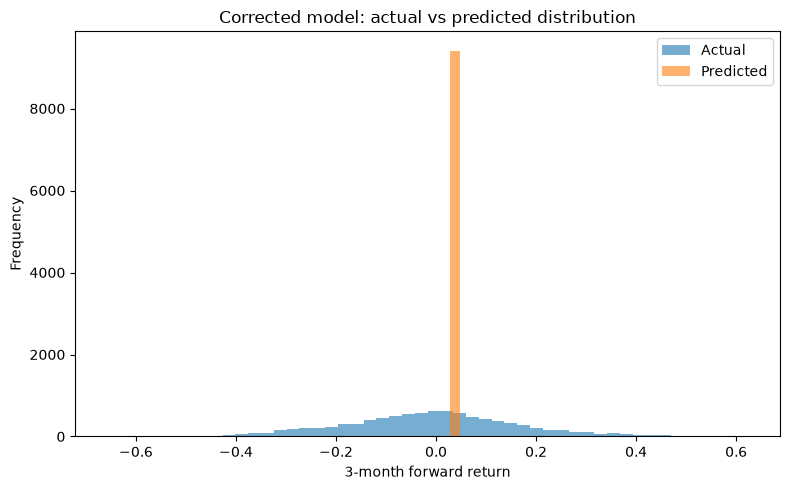

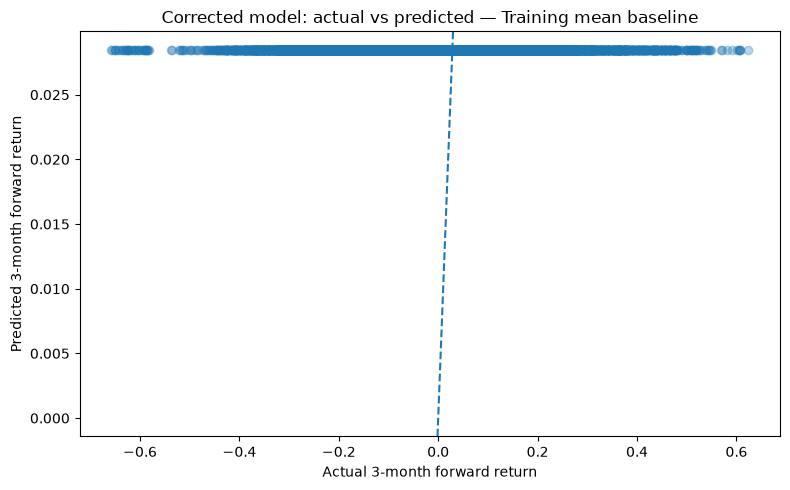

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(y_test, bins=50, alpha=0.6, label="Actual")
ax.hist(test_pred, bins=50, alpha=0.6, label="Predicted")
ax.set_xlabel("3-month forward return")
ax.set_ylabel("Frequency")
ax.set_title("Corrected model: actual vs predicted distribution")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "corrected_actual_vs_predicted_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(y_test, test_pred, alpha=0.3)
ax.set_xlabel("Actual 3-month forward return")
ax.set_ylabel("Predicted 3-month forward return")
ax.set_title(f"Corrected model: actual vs predicted — {best_model_name}")
ax.axline((0, 0), slope=1, linestyle="--")
plt.tight_layout()
plt.savefig(OUT / "corrected_actual_vs_predicted_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Save Phase 14 summary

In [9]:
summary = {
    "phase": 14,
    "target": "forward_return_3m",
    "target_source": "Phase 13 corrected targets from Phase 8 prices",
    "target_horizon": "63 future observations per ticker",
    "features_used": feature_cols,
    "train_rows": int(len(train)),
    "validation_rows": int(len(valid)),
    "test_rows": int(len(test)),
    "train_max_target_endpoint": str(train["target_endpoint_date_3m"].max()),
    "validation_start_date": str(valid["date"].min()),
    "validation_max_target_endpoint": str(valid["target_endpoint_date_3m"].max()),
    "test_start_date": str(test["date"].min()),
    "endpoint_checks": checks,
    "selected_model_by_validation_mae": best_model_name,
    "test_metrics": test_results.iloc[0].to_dict(),
    "baseline_comparison": baseline_comparison.to_dict(orient="records"),
    "warning": "Feature names were allowlisted conservatively, but feature timing still requires manual verification. This is not investment advice."
}
with open(OUT / "phase14_corrected_model_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))
print("\nOutputs saved to:", OUT)
print("Predictions saved to:", PRED_OUT)

{
  "phase": 14,
  "target": "forward_return_3m",
  "target_source": "Phase 13 corrected targets from Phase 8 prices",
  "target_horizon": "63 future observations per ticker",
  "features_used": [
    "momentum_21d",
    "momentum_63d",
    "benchmark_return_1d",
    "benchmark_volatility_21d",
    "benchmark_volatility_63d"
  ],
  "train_rows": 40447,
  "validation_rows": 6084,
  "test_rows": 9412,
  "train_max_target_endpoint": "2025-02-17 00:00:00",
  "validation_start_date": "2025-02-18 00:00:00",
  "validation_max_target_endpoint": "2025-10-31 00:00:00",
  "test_start_date": "2025-11-03 00:00:00",
  "endpoint_checks": {
    "train_endpoints_before_validation_start": true,
    "validation_endpoints_before_test_start": true,
    "train_max_endpoint": "2025-02-17 00:00:00",
    "validation_start": "2025-02-18 00:00:00",
    "validation_max_endpoint": "2025-10-31 00:00:00",
    "test_start": "2025-11-03 00:00:00",
    "train_rows": 40447,
    "validation_rows": 6084,
    "test_rows": 

## 10. Completion checklist

Before accepting the corrected metrics:
- Check that the endpoint boundary assertions passed.
- Review the Phase 13 target reconstruction comparison CSV.
- Confirm the selected predictors are point-in-time features.
- Compare corrected test MAE/RMSE with the mean baseline.
- Compare corrected results with Phase 11, but do not directly claim the scores are comparable if targets or predictors changed.
- If the reconstruction comparison shows large discrepancies, investigate target definition before proceeding.